# Amazon Product Analysis: EDA Project

**Goal:** Explore Amazon product pricing, discounts, ratings, review counts, and categories using Python. This notebook includes English comments and explanations for learning and interview preparation.

**Structure of this notebook:**

0. Import liabraries and Dataset
1. Understand the Dataset
2. Data Quality Checks
3. Clean and Prepare the Data
4. Handle Missing Values
5. Key Performance Indicators (KPIs)
6. Univariate analysis (numeric + categorical + text)
7. Bivariate analysis
8. Multivariate analysis
9. List Highly Rated Poducts with Many Ratings
10. Summary of findings

## 0. Import liabraries and Dataset

In [1]:
# Import libraries for data analysis and visualization
import pandas as pd  
import numpy as np  
import matplotlib.pyplot as plt  
import seaborn as sns  
from pathlib import Path 
import plotly.express as px
import plotly.graph_objects as go

pd.set_option('display.max_columns', None)

In [7]:
AMZ = pd.read_csv("data/amazon (2).csv")
AMZ.head(5)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


## 1. Understand the Dataset

Check the number of rows and columns, column names, data types, and sample records before cleaning.

In [8]:
# Check the number of rows and columns
print("Dataset shape:", AMZ.shape)  

# List all column names
print("\nColumn names:", AMZ.columns.tolist()) 

# Inspect data types and non-missing counts
AMZ.info()  # Summarize column data types and non-null values

# Calculate summary statistics for numeric columns where possible
AMZ.describe(include="all").T  # Summarize numeric and text columns

Dataset shape: (1465, 16)

Column names: ['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name      

,count,unique,top,freq
product_id,1465,1351,B08WRWPM22,3
product_name,1465,1337,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",5
category,1465,211,Computers&Accessories|Accessories&Peripherals|...,233
discounted_price,1465,550,₹199,53
actual_price,1465,449,₹999,120
discount_percentage,1465,92,50%,56
rating,1465,28,4.1,244
rating_count,1463,1143,"9,378",9
about_product,1465,1293,[CHARGE & SYNC FUNCTION]- This cable comes wit...,6
user_id,1465,1194,"AHIKJUDTVJ4T6DV6IUGFYZ5LXMPA,AE55KTFVNXYFD5FPY...",10


## 2. Data Quality Checks

Identify missing values, duplicate rows, and possible repeated product IDs. These checks help decide what needs cleaning.

In [9]:
# Count missing values in each column
missing_values = AMZ.isnull().sum().sort_values(ascending=False) 
display(missing_values[missing_values > 0])

# Count exact duplicate rows
print("Duplicate rows:", AMZ.duplicated().sum()) 

# Check whether product IDs repeat
print("Repeated product IDs:", AMZ["product_id"].duplicated().sum()) 

# Display the number of unique values in each column
AMZ.nunique().sort_values(ascending=False) 

rating_count    2
dtype: int64

Duplicate rows: 0
Repeated product IDs: 114


product_link           1465
img_link               1412
product_id             1351
product_name           1337
about_product          1293
review_content         1212
user_name              1194
review_id              1194
user_id                1194
review_title           1194
rating_count           1143
discounted_price        550
actual_price            449
category                211
discount_percentage      92
rating                   28
dtype: int64

## 3. Clean and Prepare the Data

Prices contain the Indian rupee symbol and commas, discount values contain `%`, and several numeric fields are stored as text. We will convert them carefully and preserve the original columns.

In [10]:
# Create a working copy so the original DataFrame remains unchanged
clean_df = AMZ.copy()  # Copy the raw data before applying cleaning steps

# Convert price text such as '₹1,099' into numeric values such as 1099.0
for column in ["discounted_price", "actual_price"]: 
    clean_df[column] = pd.to_numeric(
        clean_df[column].astype(str).str.replace("₹", "", regex=False).str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    )  # Remove currency symbols and commas, then convert invalid values to NaN

# Remove the percent sign and convert discount percentage to a number
clean_df["discount_percentage"] = pd.to_numeric(
    clean_df["discount_percentage"].astype(str).str.replace("%", "", regex=False).str.strip(),
    errors="coerce"
)  # Convert values such as '43%' into 43.0

# Convert rating to a numeric value
clean_df["rating"] = pd.to_numeric(clean_df["rating"], errors="coerce")  # Turn invalid rating text into NaN

# Remove commas from review counts and convert them to numbers
clean_df["rating_count"] = pd.to_numeric(
    clean_df["rating_count"].astype(str).str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)  # Convert values such as '43,994' into 43994.0

# Extract the broad category from the pipe-separated category path
clean_df["main_category"] = clean_df["category"].fillna("Unknown").str.split("|", regex=False).str[0]  # Keep the first category level

# Add the calculated savings amount
clean_df["savings_amount"] = clean_df["actual_price"] - clean_df["discounted_price"] 

# Review the cleaned data types
clean_df[["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count", "savings_amount"]].dtypes

clean_df.dtypes

product_id              object
product_name            object
category                object
discounted_price       float64
actual_price           float64
discount_percentage      int64
rating                 float64
rating_count           float64
about_product           object
user_id                 object
user_name               object
review_id               object
review_title            object
review_content          object
img_link                object
product_link            object
main_category           object
savings_amount         float64
dtype: object

In [11]:
clean_df.describe()

,discounted_price,actual_price,discount_percentage,rating,rating_count,savings_amount
count,1465.000000,1465.000000,1465.000000,1464.000000,1463.000000,1465.000000
mean,3125.310874,5444.990635,47.691468,4.096585,18295.541353,2319.679761
std,6944.304394,10874.826864,21.635905,0.291674,42753.864952,4604.473790
min,39.000000,39.000000,0.000000,2.000000,2.000000,0.000000
25%,325.000000,800.000000,32.000000,4.000000,1186.000000,371.000000
50%,799.000000,1650.000000,50.000000,4.100000,5179.000000,800.000000
75%,1999.000000,4295.000000,63.000000,4.300000,17336.500000,1953.000000
max,77990.000000,139900.000000,94.000000,5.000000,426973.000000,61910.000000


In [12]:
# Split the category path safely; fill missing category labels before splitting
cat_split = clean_df["category"].fillna("Unknown").astype(str).str.split("|", expand=True, regex=False)

clean_df["main_category"] = cat_split[0].str.strip()  # First level of the category path
if cat_split.shape[1] > 1:
    clean_df["sub_category"] = cat_split[1].fillna("Not specified").str.strip()  # Second level, when present
else:
    clean_df["sub_category"] = "Not specified"  # Use a clear fallback if no second level exists

clean_df[["savings_amount", "main_category", "sub_category"]].head(3)


,savings_amount,main_category,sub_category
0,700.0,Computers&Accessories,Accessories&Peripherals
1,150.0,Computers&Accessories,Accessories&Peripherals
2,1700.0,Computers&Accessories,Accessories&Peripherals


In [13]:
# Separate the dataframe into an analytical (numeric/categorical) view and a text view
analysis_df = clean_df.drop(columns=['about_product', 'user_id', 'user_name', 'review_id',
                             'review_title', 'review_content', 'img_link', 'product_link'])

txt_df = clean_df[['product_id', 'review_title', 'review_content', 'rating']].copy()

print(analysis_df.columns.tolist())
print(txt_df.columns.tolist())

['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'main_category', 'savings_amount', 'sub_category']
['product_id', 'review_title', 'review_content', 'rating']


## 4. Handle Missing Values

We will report missing values first. For analysis charts, rows missing the specific measure will be excluded from that chart rather than inventing values. If filling values is needed, the method should be chosen based on the business context.

In [14]:
# Count missing values after numeric conversion
clean_df.isnull().sum().sort_values(ascending=False)  # Recheck missing values after cleaning

# Create an analysis copy without exact duplicate rows
analysis_df = clean_df.drop_duplicates().copy()  # Remove exact duplicates and avoid changing clean_df

# Show final row count after duplicate removal
print("Rows available for analysis:", len(analysis_df))  # Report how many rows remain

Rows available for analysis: 1465


## 5. Key Performance Indicators (KPIs)

These metrics provide a quick summary of the product catalog. Average rating and price are calculated only from valid numeric values.

In [15]:
# Calculate high-level metrics for the dataset
total_products = analysis_df["product_id"].nunique()  # Count unique products
average_rating = analysis_df["rating"].mean()  # Calculate the mean of valid ratings
average_discount = analysis_df["discount_percentage"].mean()  # Calculate the mean discount percentage
average_discounted_price = analysis_df["discounted_price"].mean()  # Calculate the mean discounted price
total_categories = analysis_df["main_category"].nunique()  # Count broad product categories

# Print the KPIs in a readable format
print(f"Unique products: {total_products:,}")  # Display unique product count
print(f"Average rating: {average_rating:.2f}")  # Display average rating
print(f"Average discount: {average_discount:.2f}%")  # Display average discount percentage
print(f"Average discounted price: ₹{average_discounted_price:,.2f}")  # Display average discounted price
print(f"Main categories: {total_categories}")  # Display category count

Unique products: 1,351
Average rating: 4.10
Average discount: 47.69%
Average discounted price: ₹3,125.31
Main categories: 9


## 6. Univariate Analysis

### 6a. Numeric columns — distribution shape (histogram) and spread/outliers (box plot)

Task was destroyed but it is pending!
task: <Task pending name='Task-316' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\ersan\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-317' coro=<Kernel.shell_main() running at C:\Users\ersan\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\ersan\AppData\Local\Programs\Python\Python314\Lib\site-packages\zmq\eventloop\zmqstream.py:564]>
C:\Users\ersan\AppData\Local\Programs\Python\Python314\Lib\site-packages\matplotlib\_api\__init__.py:144: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  for k, v in kwargs.items():
Task was destroyed but it is pending!
task: <Task pending name='Task-317' coro=<Kernel.shell_main() running at C:\Users\ersan\AppData\Local\Programs\Python\Python314\Lib\site-packages\ipykernel\kernelb

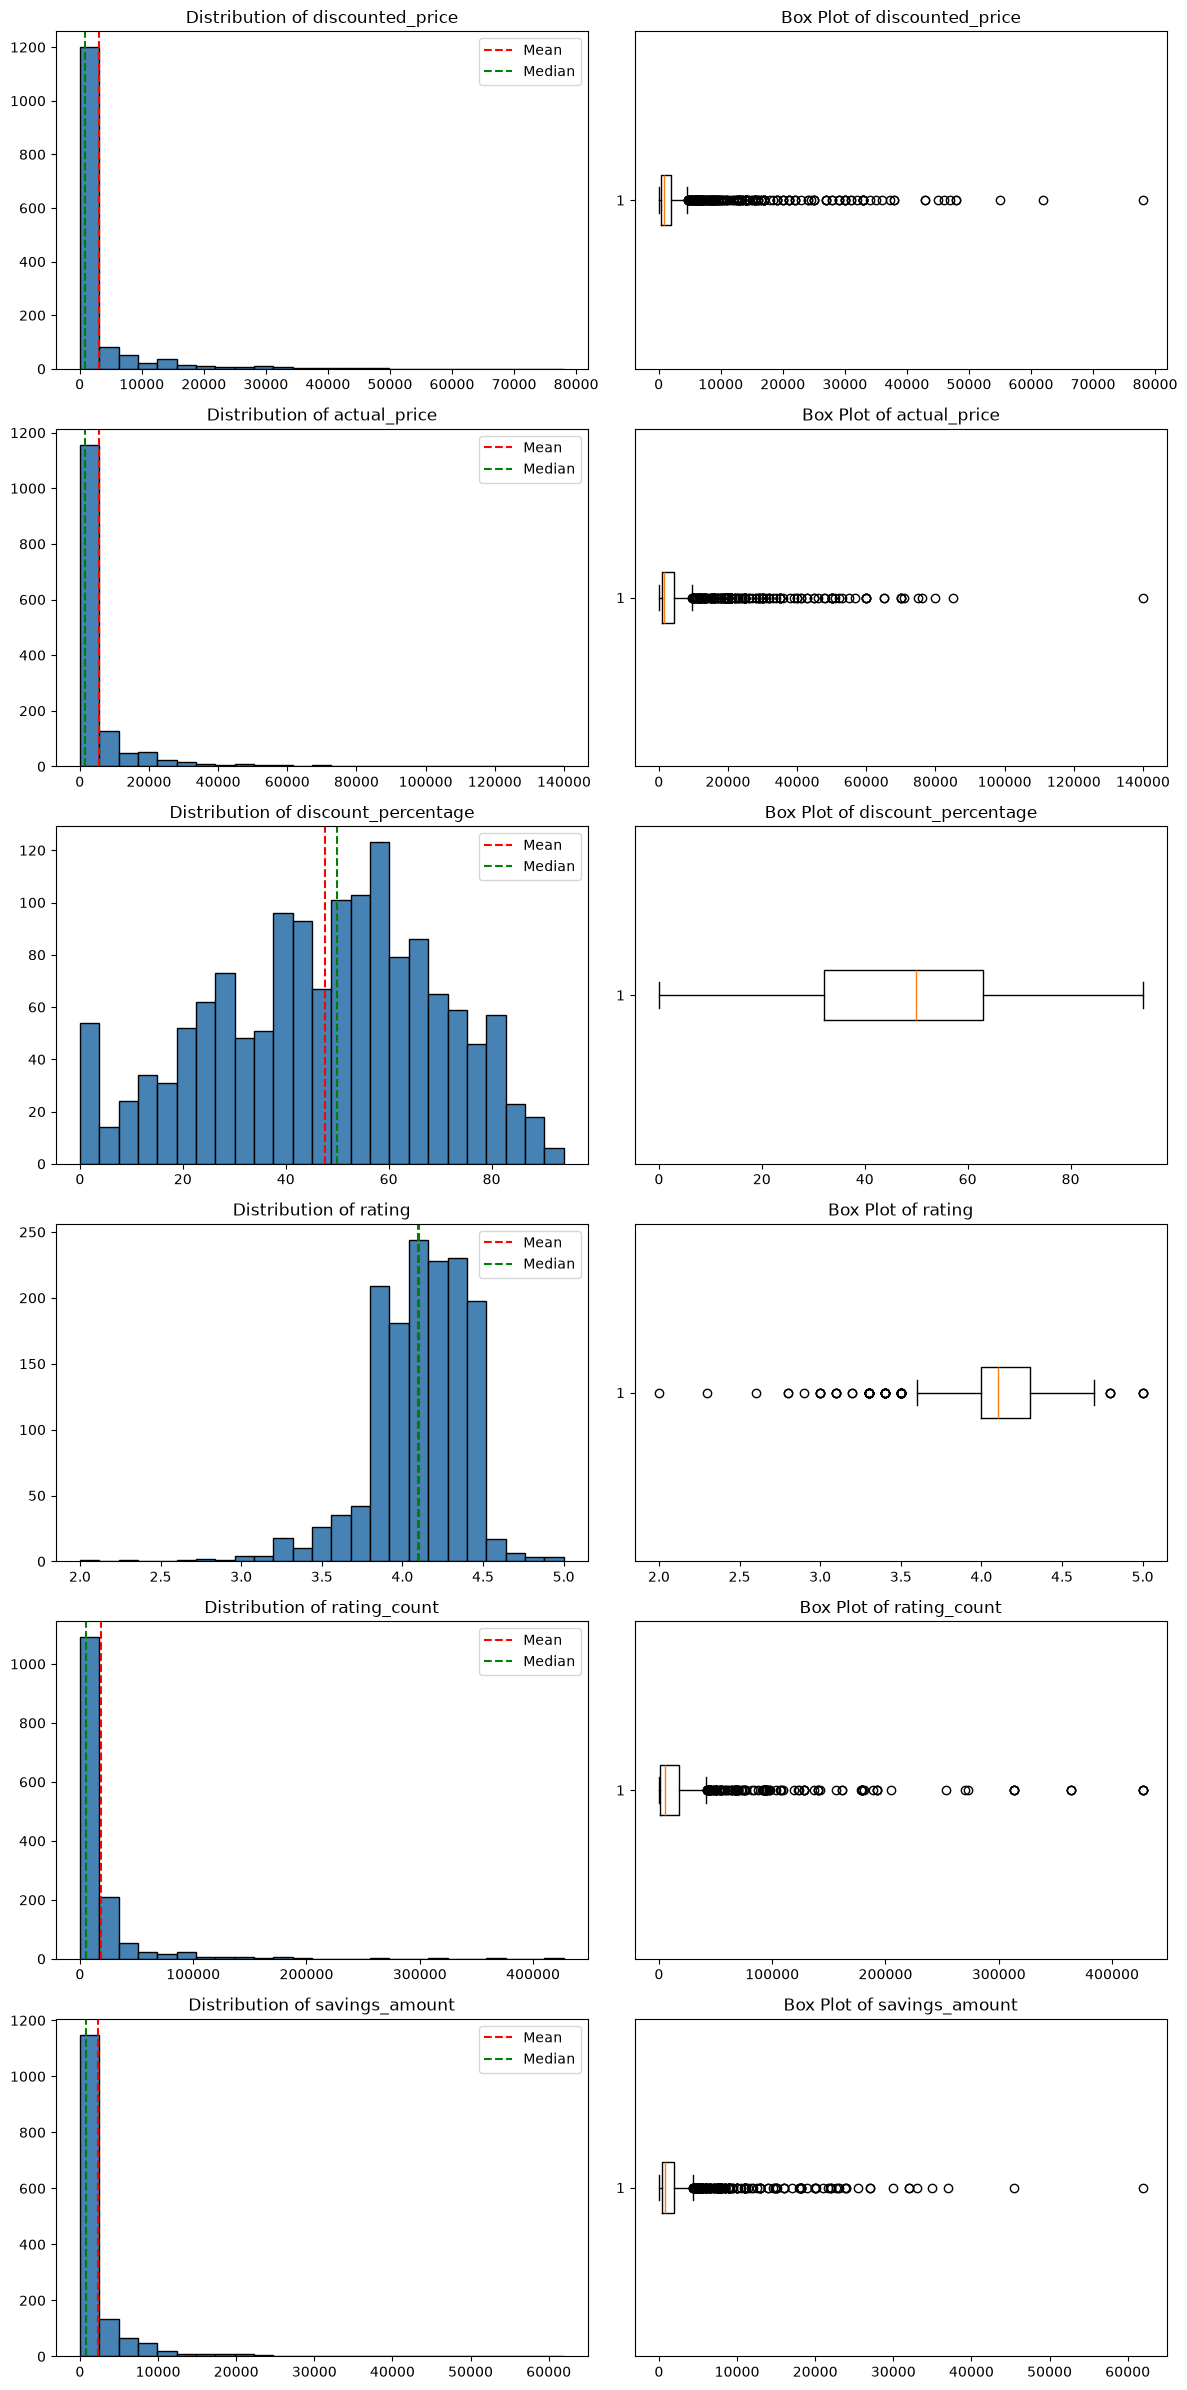

In [38]:
num_cols = clean_df.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(nrows=len(num_cols), ncols=2, figsize=(12, 4 * len(num_cols)))

for i, col in enumerate(num_cols):
    axes[i, 0].hist(clean_df[col], bins=25, color='steelblue', edgecolor='black')
    axes[i, 0].axvline(clean_df[col].mean(), color='red', linestyle='--', label='Mean')
    axes[i, 0].axvline(clean_df[col].median(), color='green', linestyle='--', label='Median')
    axes[i, 0].set_title(f'Distribution of {col}')
    axes[i, 0].legend()

   # Remove missing values before drawing the box plot
    values = clean_df[col].dropna()

  # Draw the horizontal box plot using valid numeric values
    axes[i, 1].boxplot(values, orientation="horizontal")
    axes[i, 1].set_title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

In [26]:
# Quantify the skew directly instead of eyeballing it
skew_summary = pd.DataFrame({
    'median': clean_df[num_cols].median(),
    'mean': clean_df[num_cols].mean(),
    'skew': clean_df[num_cols].skew()
})
skew_summary

,median,mean,skew
discounted_price,799.0,3125.310874,4.452395
actual_price,1650.0,5444.990635,4.559879
discount_percentage,50.0,47.691468,-0.290532
rating,4.1,4.096585,-1.242895
rating_count,5179.0,18295.541353,5.673784
savings_amount,800.0,2319.679761,5.022515


**Interpretation guidance:**
- Compare the mean, median, and skew values in the table rather than assuming every numeric column has the same distribution.
- A positive skew indicates a longer right tail; in that case, the median can describe a typical value better than the mean.
- Ratings are bounded by the rating scale, while prices and rating counts can span a much wider range.
- Treat these as descriptions of this dataset, not as universal rules. Check the actual statistics before writing final conclusions.

### 6b. Categorical columns — frequency counts


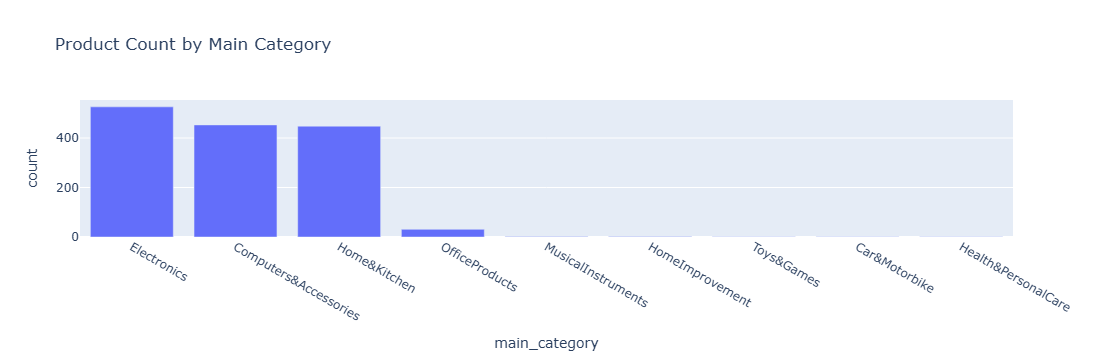

In [27]:
main_cat_counts = clean_df['main_category'].value_counts().reset_index()
main_cat_counts.columns = ['main_category', 'count']

fig = px.bar(main_cat_counts, x='main_category', y='count',
             title='Product Count by Main Category')
fig.show()

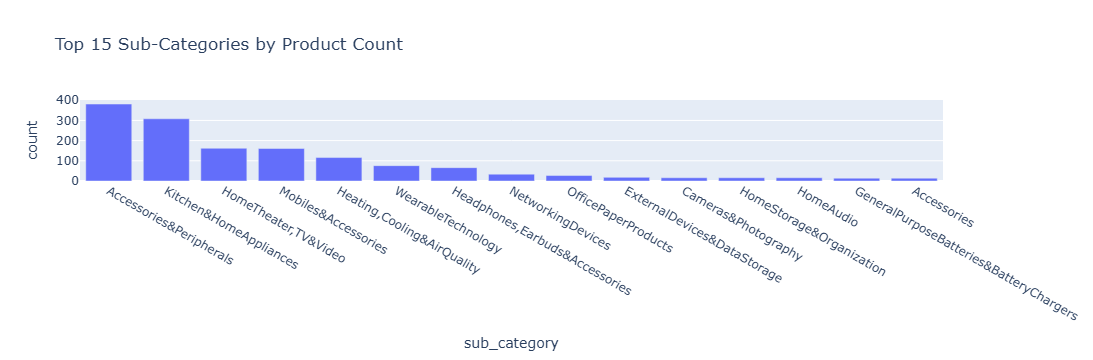

In [28]:
sub_cat_counts = clean_df['sub_category'].value_counts().reset_index()
sub_cat_counts.columns = ['sub_category', 'count']

fig = px.bar(sub_cat_counts.head(15), x='sub_category', y='count',
             title='Top 15 Sub-Categories by Product Count')
fig.show()

**Interpretation:** note which categories dominate the catalog and which are thin — a thin category (only a handful of products) will produce an unreliable-looking box plot later in the bivariate section, since a few products can't represent a "typical" price range for that category.

### 6c. Text column — review content (univariate on the text data)

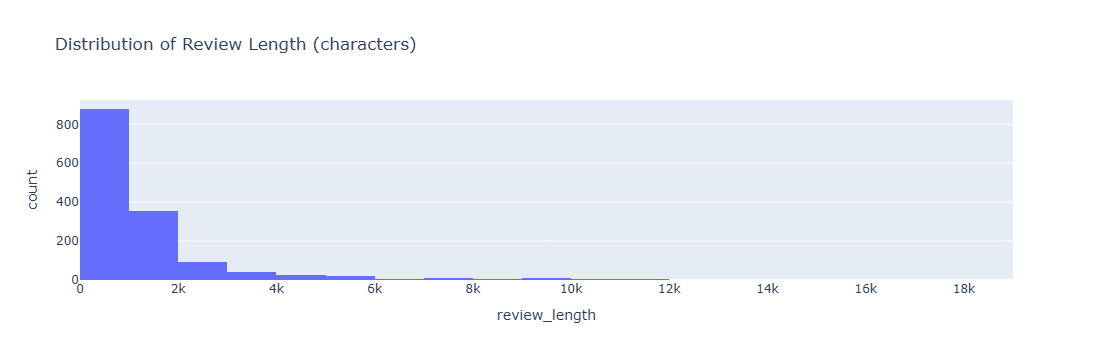

In [29]:
txt_df['review_length'] = txt_df['review_content'].astype(str).apply(len)

fig = px.histogram(txt_df, x='review_length', nbins=30,
                    title='Distribution of Review Length (characters)')
fig.show()

In [30]:
from collections import Counter
import re

all_text = ' '.join(txt_df['review_content'].astype(str).str.lower())
words = re.findall(r'\b[a-z]{4,}\b', all_text)  # words with 4+ letters, skip short stopword-ish tokens
common_words = Counter(words).most_common(15)

pd.DataFrame(common_words, columns=['word', 'frequency'])

,word,frequency
0,good,6455
1,this,4919
2,product,3947
3,with,3290
4,very,2549
5,quality,2417
6,have,2142
7,that,2133
8,price,1393
9,cable,1380


**Interpretation:** most reviews are short-to-moderate length. The most frequent words give a quick sense of what customers talk about — worth a proper stopword removal pass if you take this further, but even this rough version confirms the text data is usable and not garbage.

## 7. Bivariate Analysis

### 7a. Numeric vs Numeric

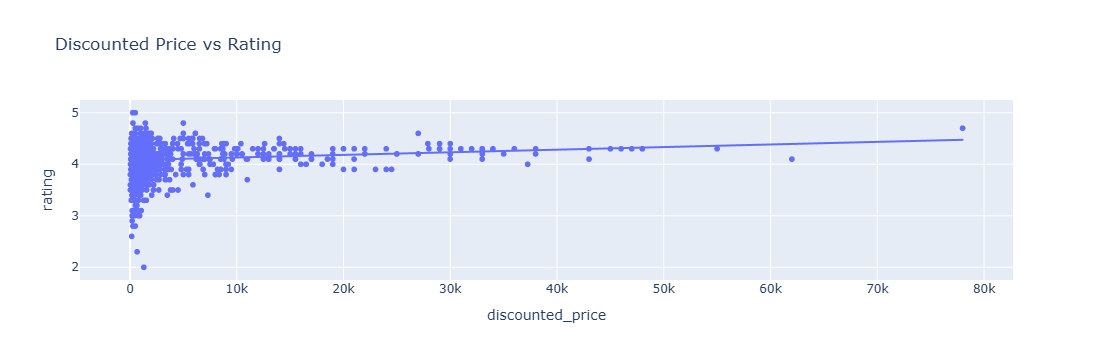

In [31]:
fig = px.scatter(analysis_df, x='discounted_price', y='rating', trendline='ols',
                  title='Discounted Price vs Rating')
fig.show()

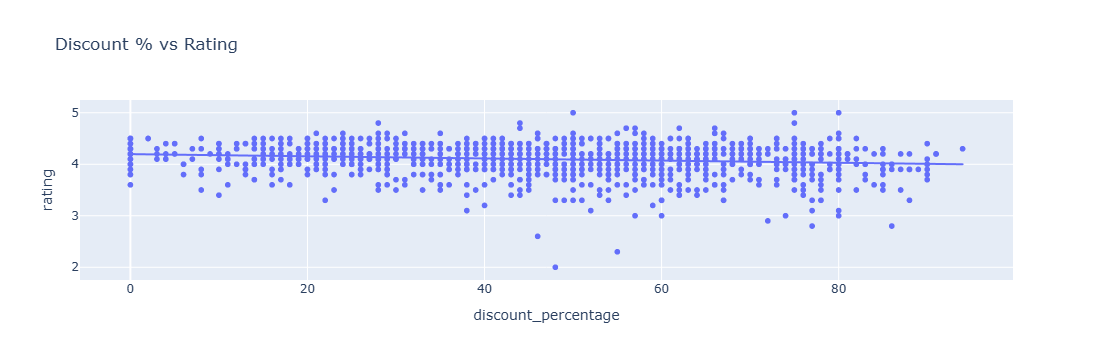

In [32]:
fig = px.scatter(analysis_df, x='discount_percentage', y='rating', trendline='ols',
                  title='Discount % vs Rating')
fig.show()

**Interpretation:** if the trendline is close to flat in both plots, that tells you price and discount level have little linear relationship with rating — i.e. cheaper or more heavily discounted products aren't systematically rated worse (or better). Worth stating explicitly rather than leaving the reader to infer it from the chart alone.

### 7b. Numeric vs Categorical

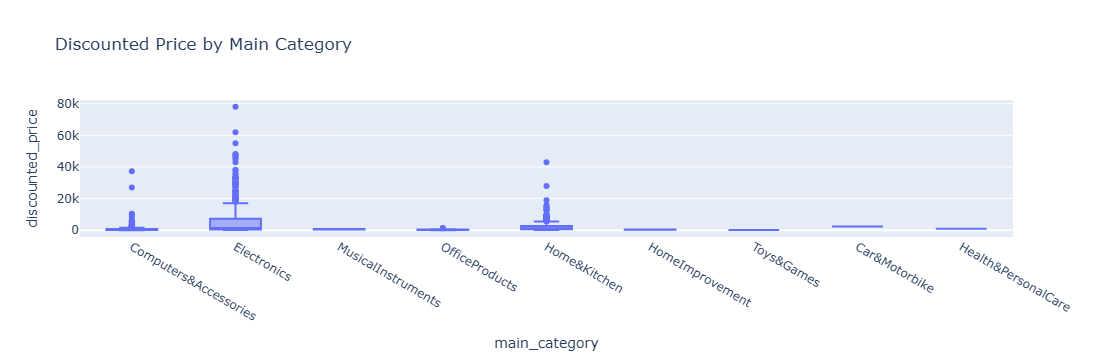

In [33]:
fig = px.box(analysis_df, x='main_category', y='discounted_price',
             title='Discounted Price by Main Category')
fig.show()

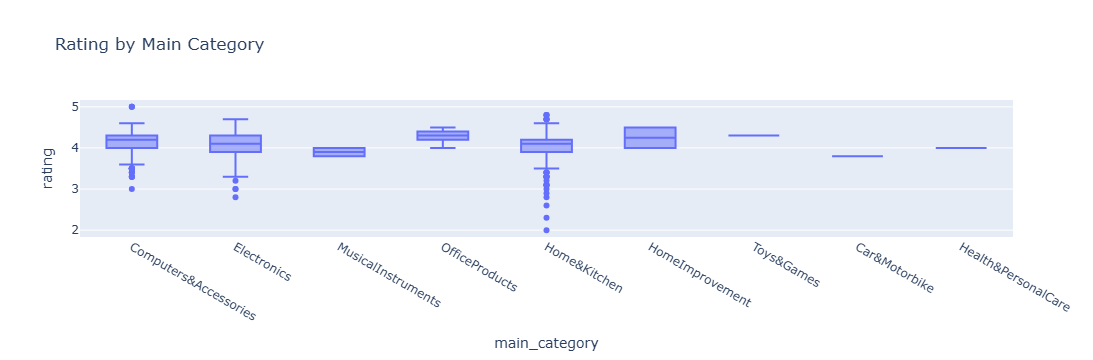

In [34]:
fig = px.box(analysis_df, x='main_category', y='rating',
             title='Rating by Main Category')
fig.show()

**Interpretation:** compare the median line and box width across categories — a category with a much higher median price, or a much wider spread, stands out here in a way the univariate price box plot alone couldn't show.

## 8. Multivariate Analysis

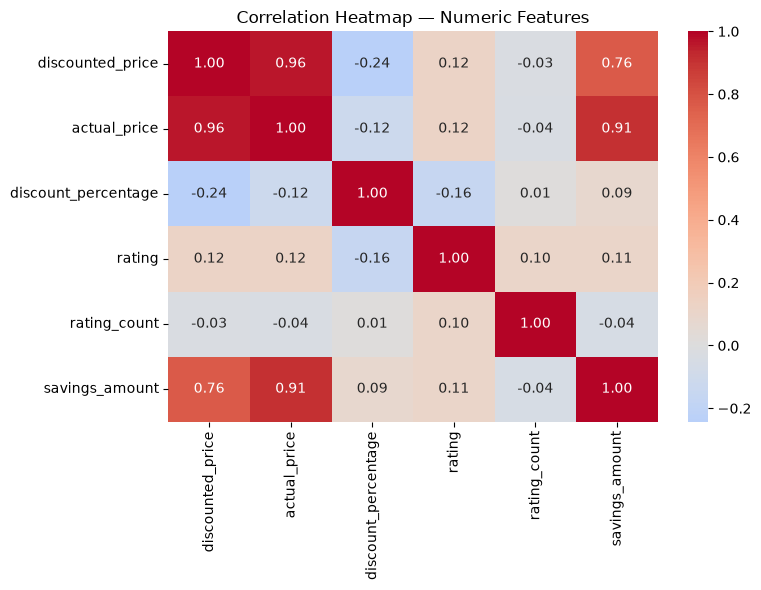

In [35]:
corr = analysis_df[['discounted_price', 'actual_price', 'discount_percentage',
                  'rating', 'rating_count', 'savings_amount']].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', ax=ax)
ax.set_title('Correlation Heatmap — Numeric Features')
plt.tight_layout()
plt.show()

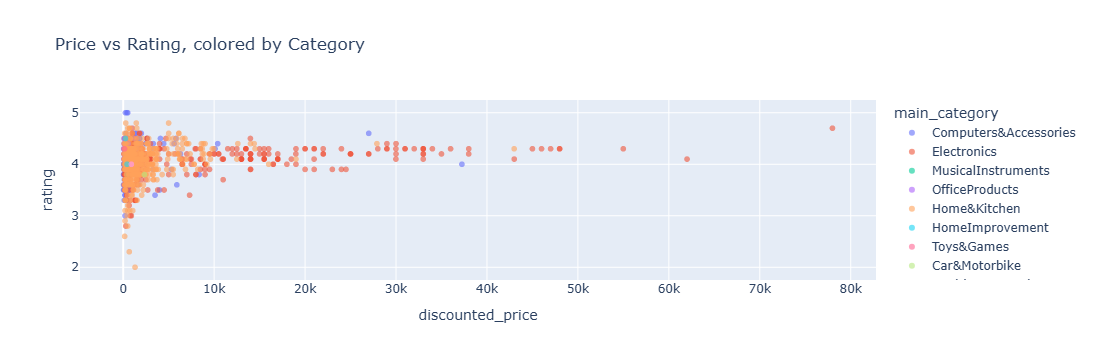

In [36]:
fig = px.scatter(analysis_df, x='discounted_price', y='rating', color='main_category',
                  title='Price vs Rating, colored by Category',
                  opacity=0.6)
fig.show()

**Interpretation:** the heatmap quantifies what the scatter plots suggested — `actual_price` and `discounted_price` are (unsurprisingly) strongly correlated with each other, while `rating` shows weak correlation with price-related columns. The color-coded scatter shows whether that weak price-rating relationship holds consistently across categories, or if it's masking different patterns within specific categories.

## 9. List Highly Rated Poducts with Many Ratings

In [37]:
top_products = analysis_df.dropna(subset=["rating", "rating_count"]).sort_values(
    ["rating", "rating_count"], ascending=[False, False]
)[["product_name", "main_category", "discounted_price", "discount_percentage", "rating", "rating_count"]].head(10)  # Rank by rating, then rating count

# Display the shortlist for further investigation
top_products  # Show products with strong ratings and rating volume

,product_name,main_category,discounted_price,discount_percentage,rating,rating_count
775,Amazon Basics Wireless Mouse | 2.4 GHz Connect...,Computers&Accessories,499.0,50,5.0,23.0
174,Syncwire LTG to USB Cable for Fast Charging Co...,Computers&Accessories,399.0,80,5.0,5.0
1145,Swiffer Instant Electric Water Heater Faucet T...,Home&Kitchen,1439.0,28,4.8,53803.0
1299,"Instant Pot Air Fryer, Vortex 2QT, Touch Contr...",Home&Kitchen,4995.0,75,4.8,3964.0
1201,"Oratech Coffee Frother electric, milk frother ...",Home&Kitchen,279.0,44,4.8,28.0
459,Spigen EZ Fit Tempered Glass Screen Protector ...,Electronics,999.0,66,4.7,7779.0
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,Electronics,77990.0,44,4.7,5935.0
1388,Campfire Spring Chef Prolix Instant Portable W...,Home&Kitchen,1499.0,57,4.7,2591.0
1275,Multifunctional 2 in 1 Electric Egg Boiling St...,Home&Kitchen,699.0,56,4.7,2300.0
1223,"FIGMENT Handheld Milk Frother Rechargeable, 3-...",Home&Kitchen,699.0,56,4.7,1729.0


## 10. Summary of Findings

Use the actual tables and charts above to confirm each point before presenting it as a result:

- **Price and review-count distributions:** compare mean, median, and skew. If strongly right-skewed, the median may better represent a typical product than the mean.
- **Ratings:** inspect the rating distribution and report the observed concentration/range rather than assuming a distribution shape.
- **Discount percentage vs rating:** use the scatter plot and correlation result to describe the strength and direction of any linear association. Correlation does not prove causation.
- **Category mix:** use the category frequency chart to identify categories with many or few records. Be cautious when interpreting categories with very small sample sizes.
- **Missing values:** the notebook reports missing values after type conversion, but it does not remove every row with any missing value. Charts or calculations that use a particular field generally exclude rows missing that field. Do not claim that all missing rows were dropped unless you explicitly run that step and verify the row counts.

**Possible next steps:** check unusual values and category parsing, add stopword removal for text analysis, compare median prices across categories, and consider a model only after validating data quality and defining a clear target.
